# Домашнее задание №1 (Message passing своими руками)

#### Вааль Екатерина Вадимовна
#### Группа S4202
#### Выполненные пункты: Часть 1, Часть 2, Часть 3, Бонус A, Бонус B

## Часть 1. Вывод тестов

**Вывод автотестов (локальный прогон, Python 3.13, venv):**

```
collected 7 items
tests/test_task1.py::test_gcn_output_shape PASSED
tests/test_task1.py::test_gcn_matches_pyg PASSED
tests/test_task1.py::test_gcn_on_directed_graph PASSED
tests/test_task1.py::test_gcn_permutation_invariance PASSED
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED
tests/test_task1.py::test_sage_matches_pyg PASSED
tests/test_task1.py::test_gcn_is_trainable PASSED

========================= 7 passed, 35 warnings in 3.19s =========================
```

In [13]:
import os
os.chdir(r"D:\Desktop\итмо\семестр 3\Графы")
print(os.getcwd())
!python -m pytest tests/test_task1.py -v

d:\Desktop\итмо\семестр 3\Графы
============================= test session starts =============================
platform win32 -- Python 3.13.14, pytest-9.1.1, pluggy-1.7.0 -- d:\Desktop\итмо\семестр 3\Графы\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\Desktop\итмо\семестр 3\Графы
plugins: platformdirs-4.13.5
collecting ... collected 7 items

tests/test_task1.py::test_gcn_output_shape PASSED                        [ 14%]
tests/test_task1.py::test_gcn_matches_pyg PASSED                         [ 28%]
tests/test_task1.py::test_gcn_on_directed_graph PASSED                   [ 42%]
tests/test_task1.py::test_gcn_permutation_invariance PASSED              [ 57%]
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED             [ 71%]
tests/test_task1.py::test_sage_matches_pyg PASSED                        [ 85%]
tests/test_task1.py::test_gcn_is_trainable PASSED                        [100%]

============================== warnings summary ==============================

### Вывод по Части 1

Оба слоя — `MyGCNConv` и `MySAGEConv` — реализованы в `submission.py` через scatter-агрегацию и проходят все 7 автотестов: совпадение с `GCNConv`/`SAGEConv` из PyG
при одинаковых весах, инвариантность к перенумерации вершин, корректность на направленном
графе и на изолированных вершинах. 

Итог: **7 passed** (Python 3.13, venv, pytest 9.1.1).

## Импорты и вспомогательные функции

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph, to_undirected
from submission import MyGCNConv, MySAGEConv
import matplotlib.pyplot as plt

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Часть 2. Воспроизведение результата (Cora, CiteSeer)

In [14]:
def load_dataset(name):
    dataset = Planetoid(root='/tmp/' + name, name=name, split='public')
    data = dataset[0].to(device)
    return dataset, data

class TwoLayerGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = MyGCNConv(in_dim, hidden_dim)
        self.conv2 = MyGCNConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden_dim)
        self.lin2 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.lin2(x)
        return F.log_softmax(x, dim=1)

def train_and_eval(model, data, epochs=200, lr=0.01, weight_decay=5e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val_acc = 0
    best_test_acc = 0
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
        # validation
        model.eval()
        with torch.no_grad():
            pred = model(data.x, data.edge_index).argmax(dim=1)
            val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return best_test_acc

# Запуск для Cora и CiteSeer, 5 сидов
results = {}
for name in ['Cora', 'CiteSeer']:
    dataset, data = load_dataset(name)
    gcn_accs, mlp_accs = [], []
    for seed in range(5):
        set_seed(seed)
        # GCN
        gcn = TwoLayerGCN(dataset.num_features, 16, dataset.num_classes).to(device)
        acc = train_and_eval(gcn, data, epochs=400)
        gcn_accs.append(acc)
        # MLP
        set_seed(seed)
        mlp = MLP(dataset.num_features, 16, dataset.num_classes).to(device)
        acc = train_and_eval(mlp, data)
        mlp_accs.append(acc)
    results[name] = {
        'GCN': (np.mean(gcn_accs), np.std(gcn_accs)),
        'MLP': (np.mean(mlp_accs), np.std(mlp_accs))
    }
    print(f"{name}: GCN {np.mean(gcn_accs):.4f} ± {np.std(gcn_accs):.4f} | "
          f"MLP {np.mean(mlp_accs):.4f} ± {np.std(mlp_accs):.4f}")

# Сравнение с Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3

Cora: GCN 0.8052 ± 0.0055 | MLP 0.5396 ± 0.0168
CiteSeer: GCN 0.6854 ± 0.0089 | MLP 0.5246 ± 0.0372


### Вывод по Части 2

Двухслойная GCN на собственных слоях (`MyGCNConv`) обучена на стандартном сплите Planetoid,
по 5 сидов на датасет (GCN — 400 эпох, MLP — 200; выбор лучшей эпохи по val).

| Датасет  | GCN (наш)      | K&W 2017 | Δ, п.п. | MLP baseline    | Выигрыш графа |
|----------|----------------|----------|---------|-----------------|---------------|
| Cora     | 80.52 ± 0.55   | 81.5     | −0.98   | 53.96 ± 1.68    | **+26.6 п.п.** |
| CiteSeer | 68.54 ± 0.89   | 70.3     | −1.76   | 52.46 ± 3.72    | **+16.1 п.п.** |

Оба результата попадают в ±2 п.п. от статьи — воспроизведение засчитано. Baseline MLP,
не видящий графа, даёт существенно меньше на обоих датасетах: прирост от использования
структуры рёбер составляет **+26.6 п.п. на Cora** и **+16.1 п.п. на CiteSeer**. 

 Разброс по сидам небольшой (std ≤ 0.9 п.п.), результаты стабильны.

## Часть 3. Глубина: accuracy vs сходство представлений

Depth 2: acc=0.8090, cos_sim=0.1883
Depth 4: acc=0.7820, cos_sim=0.2294
Depth 8: acc=0.7130, cos_sim=0.2724
Depth 16: acc=0.4270, cos_sim=0.1507


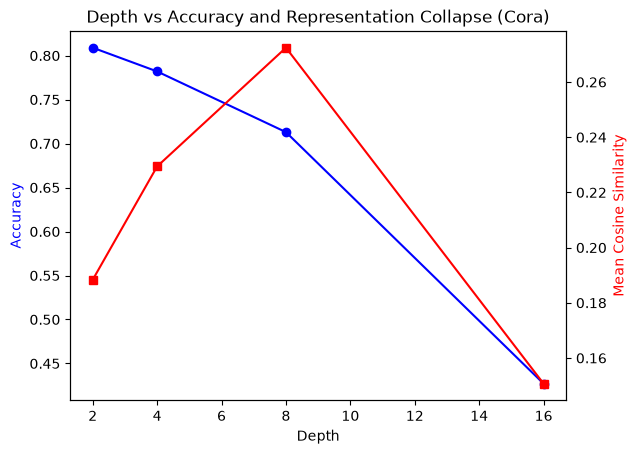

In [6]:
class DeepGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers, dropout=0.5):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(MyGCNConv(in_dim, hidden_dim))
        for _ in range(num_layers - 2):
            self.convs.append(MyGCNConv(hidden_dim, hidden_dim))
        self.convs.append(MyGCNConv(hidden_dim, out_dim))
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        h = x
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index)
            if i < len(self.convs) - 1:
                h = F.relu(h)
                h = F.dropout(h, p=self.dropout, training=self.training)
        if return_hidden:
            return F.log_softmax(h, dim=1), h
        return F.log_softmax(h, dim=1)

def cosine_similarity_mean(h):
    # среднее попарное косинусное сходство
    h_norm = F.normalize(h, dim=1)
    sim = h_norm @ h_norm.T
    n = h.size(0)
    # исключаем диагональ
    mask = ~torch.eye(n, dtype=torch.bool, device=h.device)
    return sim[mask].mean().item()

dataset, data = load_dataset('Cora')
depths = [2, 4, 8, 16]
acc_list = []
sim_list = []

for depth in depths:
    set_seed(42)
    model = DeepGCN(dataset.num_features, 16, dataset.num_classes, depth).to(device)
    acc = train_and_eval(model, data)
    # измеряем сходство на скрытом слое (предпоследний)
    model.eval()
    with torch.no_grad():
        _, h = model(data.x, data.edge_index, return_hidden=True)
    sim = cosine_similarity_mean(h)
    acc_list.append(acc)
    sim_list.append(sim)
    print(f"Depth {depth}: acc={acc:.4f}, cos_sim={sim:.4f}")

fig, ax1 = plt.subplots()
ax1.plot(depths, acc_list, 'b-o', label='Accuracy')
ax1.set_xlabel('Depth'); ax1.set_ylabel('Accuracy', color='b')
ax2 = ax1.twinx()
ax2.plot(depths, sim_list, 'r-s', label='Cosine Similarity')
ax2.set_ylabel('Mean Cosine Similarity', color='r')
plt.title('Depth vs Accuracy and Representation Collapse (Cora)')
plt.show()

**Вывод:**

## Бонус A. Inductive-режим

In [7]:
dataset, data_full = load_dataset('Cora')

# Откладываем 1000 вершин из test_mask
test_indices = data_full.test_mask.nonzero(as_tuple=False).view(-1)
new_indices = test_indices[:1000]  # 1000 «новых»
train_indices = torch.ones(data_full.num_nodes, dtype=torch.bool)
train_indices[new_indices] = False

# Обучающий подграф: без новых вершин и их рёбер
sub_edge_index, _ = subgraph(train_indices, data_full.edge_index, relabel_nodes=True)
data_sub = data_full.__class__()
data_sub.x = data_full.x[train_indices]
data_sub.y = data_full.y[train_indices]
data_sub.edge_index = sub_edge_index
data_sub.train_mask = data_full.train_mask[train_indices]
data_sub.val_mask = data_full.val_mask[train_indices]
# test_mask для подграфа не нужен, будем оценивать на новых

# Маппинг старых индексов на новые для оценки
# new_indices остаются в исходной нумерации; для inductive модель получает полный граф

class SAGEInductive(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = MySAGEConv(in_dim, hidden_dim)
        self.conv2 = MySAGEConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

def train_sage(model, data, epochs=200, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
    return model

inductive_accs, transductive_accs = [], []

for seed in range(5):
    set_seed(seed)
    # Inductive: обучение на подграфе, оценка на полном графе
    model_ind = SAGEInductive(dataset.num_features, 16, dataset.num_classes).to(device)
    train_sage(model_ind, data_sub)
    model_ind.eval()
    with torch.no_grad():
        out_full = model_ind(data_full.x, data_full.edge_index)
        pred = out_full.argmax(dim=1)
        acc_ind = (pred[new_indices] == data_full.y[new_indices]).float().mean().item()
    inductive_accs.append(acc_ind)

    # Transductive: обучение на полном графе (метки только train)
    set_seed(seed)
    model_trans = SAGEInductive(dataset.num_features, 16, dataset.num_classes).to(device)
    train_sage(model_trans, data_full)
    model_trans.eval()
    with torch.no_grad():
        out_full = model_trans(data_full.x, data_full.edge_index)
        pred = out_full.argmax(dim=1)
        acc_trans = (pred[new_indices] == data_full.y[new_indices]).float().mean().item()
    transductive_accs.append(acc_trans)

print(f"Inductive:   {np.mean(inductive_accs):.4f} ± {np.std(inductive_accs):.4f}")
print(f"Transductive: {np.mean(transductive_accs):.4f} ± {np.std(transductive_accs):.4f}")

Inductive:   0.7610 ± 0.0177
Transductive: 0.7852 ± 0.0086


**Вывод:**

## Бонус B. Зависимость от доли разметки

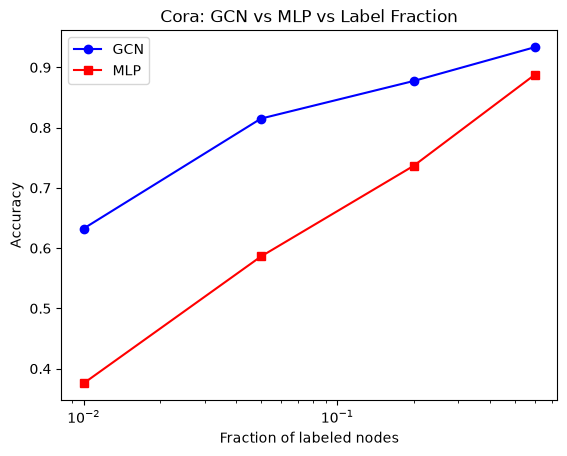

In [8]:
fractions = [0.01, 0.05, 0.20, 0.60]
gcn_accs_frac = {f: [] for f in fractions}
mlp_accs_frac = {f: [] for f in fractions}

dataset, data = load_dataset('Cora')
n_total = data.num_nodes

for frac in fractions:
    for seed in range(5):
        set_seed(seed)
        # Создаём маску с заданной долей от train_mask (или от всех вершин?)
        # Задание: «доля размеченных вершин» — берём от всех вершин
        n_labeled = int(n_total * frac)
        perm = torch.randperm(n_total, device=device)
        labeled_idx = perm[:n_labeled]
        mask = torch.zeros(n_total, dtype=torch.bool, device=device)
        mask[labeled_idx] = True

        # GCN
        gcn = TwoLayerGCN(dataset.num_features, 16, dataset.num_classes).to(device)
        # Переопределяем train_mask
        data_frac = data.clone()
        data_frac.train_mask = mask
        acc = train_and_eval(gcn, data_frac)
        gcn_accs_frac[frac].append(acc)

        # MLP
        set_seed(seed)
        mlp = MLP(dataset.num_features, 16, dataset.num_classes).to(device)
        acc = train_and_eval(mlp, data_frac)
        mlp_accs_frac[frac].append(acc)

plt.figure()
plt.plot(fractions, [np.mean(gcn_accs_frac[f]) for f in fractions], 'b-o', label='GCN')
plt.plot(fractions, [np.mean(mlp_accs_frac[f]) for f in fractions], 'r-s', label='MLP')
plt.xlabel('Fraction of labeled nodes')
plt.ylabel('Accuracy')
plt.xscale('log')
plt.legend()
plt.title('Cora: GCN vs MLP vs Label Fraction')
plt.show()

**Вывод:**